# 02. Branch and bound: from bounds to a certificate

Notebook 01 built lower bounds of $f$ on a box. This notebook uses them to find
a **global** minimum and to prove it, with spatial branch and bound
[falk1969algorithm, horst1990global].

## The algorithm

Keep a list of open boxes, each with a lower bound $\ell(B) \le \min_{x\in B} f(x)$,
and the best point found so far, the incumbent, with value $U$ (an upper bound
on $f^*$). Repeat:

1. **Select** the open box with the smallest lower bound; the global lower
   bound is $L = \min_B \ell(B)$.
2. **Branch**: split it in two along one coordinate.
3. **Bound** each child: compute $\ell(B)$ from the relaxations, and evaluate
   $f$ at a candidate point (refined by a local solver) to improve $U$.
4. **Prune** every box with $\ell(B) > U - \varepsilon$: it cannot contain a
   point better than the incumbent.

Stop when

$$ U - L \;\le\; \max\big(\varepsilon_{\text{abs}},\ \varepsilon_{\text{rel}}\,|U|\big). $$

At that point $L \le f^* \le U$ is a **certificate**: no point of the box can
be better than the incumbent by more than the tolerance. A local solver or a
multistart can find the same point, but it cannot give this guarantee.

jaxglobal runs the bounding step for a whole batch of boxes at once with
`jax.jit(jax.vmap(...))`, and tightens boxes before bounding them
(feasibility-, optimality- and duality-based bound tightening).

In [1]:
import os
import pathlib
import sys

os.environ.setdefault("RUST_LOG", "warn")  # keep the local NLP solver's info messages out of the output

ROOT = pathlib.Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle

from jaxglobal import make_bounder, minimize
from jaxglobal.problems import PROBLEMS, six_hump_camel

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})

## Solving one problem

The six-hump camel function on $[-3,3]\times[-2,2]$ has six local minima, two
of them global, with $f^* = -1.0316$ at $\pm(0.0898, -0.7127)$. The whole
solver call is one line:

In [2]:
lo, hi = np.array([-3.0, -2.0]), np.array([3.0, 2.0])
r = minimize(six_hump_camel, lo, hi, abs_tol=1e-6, rel_tol=1e-6)
r

Result(status='optimal', fun=-1.0316285, lower_bound=-1.0316292, gap=7.11e-07, x=[-0.089842  0.712656], nodes=23, iterations=7, time=2.01s)

`status="optimal"` means the gap $U-L$ closed to the tolerance. The result also
says whether the returned point was re-checked in float64 outside JIT
(`verified`), and by how much it violates the box or constraints
(`max_violation`, zero here):

In [3]:
print("verified:", r.verified, " max_violation:", r.max_violation)
print(f"certificate: {r.lower_bound:.8f} <= f* <= {r.fun:.8f}")

verified: True  max_violation: 0.0
certificate: -1.03162916 <= f* <= -1.03162845


## What gets pruned

To see branch and bound at work, here is a stripped-down version run by hand:
start from the whole box, split every surviving box into four quarters at each
level, bound all of them in one vectorized call with `make_bounder`, and drop
the ones whose lower bound is above the incumbent $U$ found above. (The real
solver splits one coordinate at a time and picks boxes by lower bound, but the
pruning logic is the same.)

In [4]:
bound = jax.jit(jax.vmap(make_bounder(six_hump_camel, univariate=True, alphabb=True)))
U, tol = r.fun, 1e-6


def split4(blo, bhi):
    mid = 0.5 * (blo + bhi)
    out_lo, out_hi = [], []
    for sa in (0, 1):
        for sb in (0, 1):
            s = np.array([sa, sb])
            out_lo.append(np.where(s, mid, blo))
            out_hi.append(np.where(s, bhi, mid))
    return np.concatenate(out_lo), np.concatenate(out_hi)


levels = []
blo, bhi = lo[None, :], hi[None, :]
for level in range(8):
    lb = np.asarray(bound(jnp.asarray(blo), jnp.asarray(bhi))[0])
    keep = lb <= U - tol
    levels.append((blo, bhi, keep, lb))
    blo, bhi = split4(blo[keep], bhi[keep])

for k, (a, b, keep, lb) in enumerate(levels):
    area = np.prod(b - a, axis=1)[keep].sum() / np.prod(hi - lo)
    print(f"level {k}: {len(keep):5d} boxes bounded, {keep.sum():4d} survive, surviving area {area:.2e} of the domain")

level 0:     1 boxes bounded,    1 survive, surviving area 1.00e+00 of the domain
level 1:     4 boxes bounded,    2 survive, surviving area 5.00e-01 of the domain
level 2:     8 boxes bounded,    2 survive, surviving area 1.25e-01 of the domain
level 3:     8 boxes bounded,    2 survive, surviving area 3.12e-02 of the domain
level 4:     8 boxes bounded,    2 survive, surviving area 7.81e-03 of the domain
level 5:     8 boxes bounded,    2 survive, surviving area 1.95e-03 of the domain
level 6:     8 boxes bounded,    4 survive, surviving area 9.77e-04 of the domain
level 7:    16 boxes bounded,    2 survive, surviving area 1.22e-04 of the domain


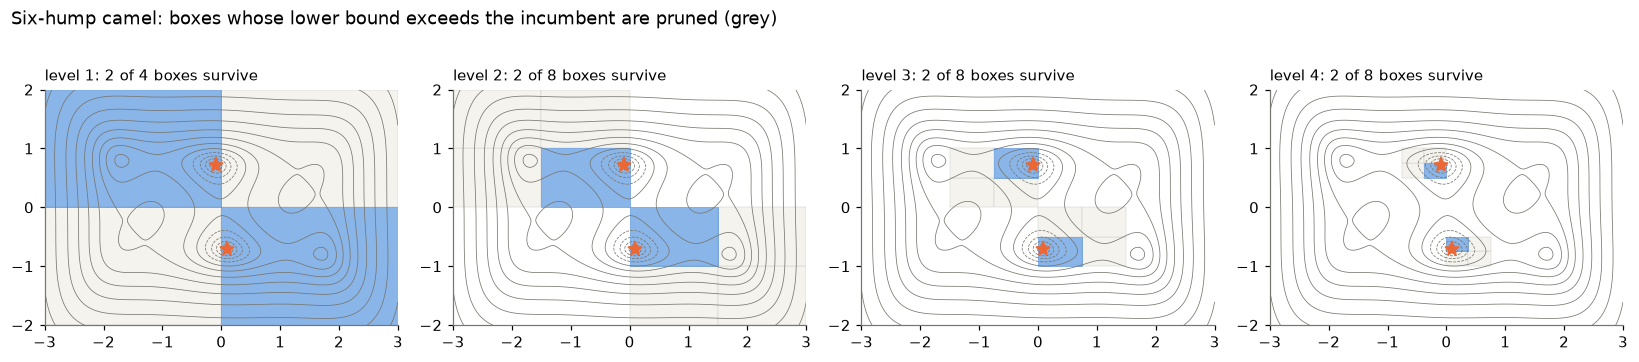

In [5]:
g1, g2 = np.linspace(-3, 3, 241), np.linspace(-2, 2, 161)
A, B = np.meshgrid(g1, g2)
Fz = np.asarray(jax.vmap(six_hump_camel)(jnp.asarray(np.c_[A.ravel(), B.ravel()]))).reshape(A.shape)

show = [1, 2, 3, 4]
fig, axes = plt.subplots(1, len(show), figsize=(15, 3.4))
for ax, k in zip(axes, show):
    a, b, keep, _ = levels[k]
    ax.contour(A, B, np.log(Fz - Fz.min() + 0.05), levels=14, colors=MUTED, linewidths=0.5)
    alive = [Rectangle(p, *(q - p)) for p, q in zip(a[keep], b[keep])]
    dead = [Rectangle(p, *(q - p)) for p, q in zip(a[~keep], b[~keep])]
    ax.add_collection(PatchCollection(dead, facecolor="#f4f3ee", edgecolor="0.8", lw=0.3))
    ax.add_collection(PatchCollection(alive, facecolor=BLUE, alpha=0.55, edgecolor=BLUE, lw=0.5))
    ax.plot([0.0898, -0.0898], [-0.7127, 0.7127], "*", color=ORANGE, ms=10)
    ax.set_xlim(-3, 3); ax.set_ylim(-2, 2); ax.set_aspect("equal"); ax.grid(False)
    ax.set_title(f"level {k}: {keep.sum()} of {len(keep)} boxes survive", loc="left", fontsize=10)
fig.suptitle("Six-hump camel: boxes whose lower bound exceeds the incumbent are pruned (grey)", x=0.01, ha="left")
fig.tight_layout()

The relaxations are tight enough that pruning is close to perfect: from level
1 on, only the box holding each global minimum (stars) survives, and the
surviving area falls by the full factor of four per level. (At level 6 four
boxes survive because each minimum lies near the edge of its box, so a
neighbour cannot be ruled out yet; one level later it can.) Every grey box
has been **proved** not to contain a point better than the incumbent, so
the rest of the domain, including the four non-global local minima, never
has to be looked at again.

## Convergence of the certificate

`Result.history` records, for every iteration, the number of nodes, the global
lower bound $L$ and the incumbent $U$. For the six-hump camel:

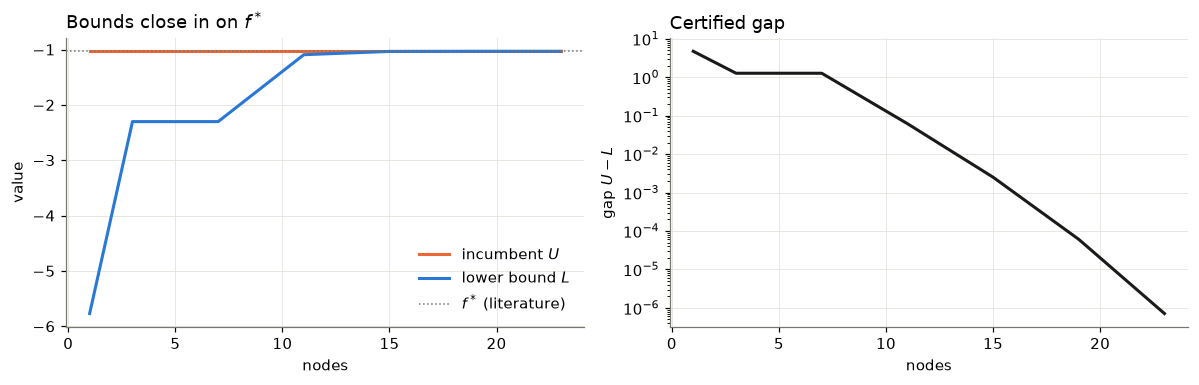

In [6]:
h = np.array(r.history)  # (iteration, nodes, L, U, open boxes)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.plot(h[:, 1], h[:, 3], color=ORANGE, lw=2, label="incumbent $U$")
ax1.plot(h[:, 1], h[:, 2], color=BLUE, lw=2, label="lower bound $L$")
ax1.axhline(-1.031628453489877, color=MUTED, ls=":", lw=1, label="$f^*$ (literature)")
ax1.set_xlabel("nodes"); ax1.set_ylabel("value"); ax1.legend(frameon=False)
ax1.set_title("Bounds close in on $f^*$", loc="left")
ax2.semilogy(h[:, 1], np.maximum(h[:, 3] - h[:, 2], 1e-12), color=INK, lw=2)
ax2.set_xlabel("nodes"); ax2.set_ylabel("gap $U - L$")
ax2.set_title("Certified gap", loc="left")
fig.tight_layout()

The local solver finds the global minimum at the root node; from then on $U$
does not change, and the remaining 22 nodes go into raising the lower bound $L$
until it meets $U$. That is the price of the certificate, and the reason
tight relaxations matter.

The same plot for four harder problems, from 2 to 6 variables:

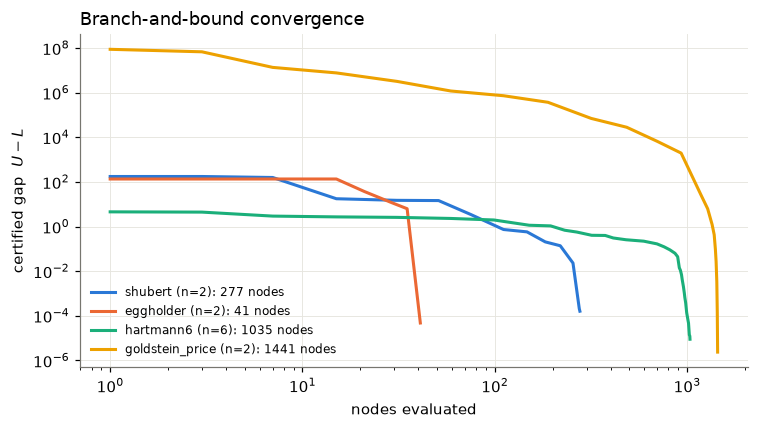

In [7]:
names = ["shubert", "eggholder", "hartmann6", "goldstein_price"]
fig, ax = plt.subplots(figsize=(7, 4))
for name, c in zip(names, [BLUE, ORANGE, AQUA, YELLOW]):
    p = next(q for q in PROBLEMS if q.name == name)
    rr = minimize(p.f, p.lo, p.hi, abs_tol=1e-5, rel_tol=1e-6)
    hh = np.array(rr.history)
    ax.plot(hh[:, 1], np.maximum(hh[:, 3] - hh[:, 2], 1e-7), color=c, lw=2, label=f"{name} (n={p.lo.size}): {rr.nodes} nodes")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("nodes evaluated"); ax.set_ylabel("certified gap  $U - L$")
ax.set_title("Branch-and-bound convergence", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(ROOT / "figures" / "convergence.png", dpi=150)

The pattern is the same in each case: a long plateau while the boxes are
still large and the bounds loose, then a steep drop once the boxes around the
global minima are small enough for the second-order convergence of
notebook 01 to take over. The gap axis spans different ranges because the
functions do (Goldstein–Price takes values up to about $10^6$ on its box).

## What the bounding options buy

Tighter bounds mean fewer nodes. The Shubert function (a product of two
trigonometric sums with 18 global minima) shows the effect of the main switches:

* `univariate` and `alphabb`: tighter envelopes of univariate functions and the
  αBB underestimator, on top of plain McCormick;
* `fbbt`, `obbt`, `dbbt`: feasibility-, optimality- and duality-based bound
  tightening, which shrink a box before it is bounded [puranik2017domain, ryoo1996branchandreduce].

In [8]:
p = next(q for q in PROBLEMS if q.name == "shubert")
configs = {
    "default": {},
    "no envelopes / αBB": dict(univariate=False, alphabb=False),
    "no bound tightening": dict(fbbt=False, obbt=False, dbbt=False),
}
print(f"{'configuration':22s} {'status':>8s} {'nodes':>7s} {'f':>12s} {'L':>12s}")
for label, kw in configs.items():
    rr = minimize(p.f, p.lo, p.hi, abs_tol=1e-5, rel_tol=1e-6, **kw)
    print(f"{label:22s} {rr.status:>8s} {rr.nodes:7d} {rr.fun:12.5f} {rr.lower_bound:12.5f}")

configuration            status   nodes            f            L
default                 optimal     277   -186.73091   -186.73107


no envelopes / αBB      optimal    1471   -186.73091   -186.73106


no bound tightening     optimal     555   -186.73091   -186.73109


Every configuration returns the same certified optimum; only the amount of
work changes. Dropping the univariate envelopes and αBB costs about five times
as many nodes (1471 vs 277), and dropping bound tightening about twice as
many (555). All of these are options of `minimize`, and none of them asks
anything more of the user than the Python function.

## Summary

* Branch and bound turns valid lower bounds into a certificate
  $L \le f^* \le U$ by splitting boxes and discarding those that provably
  cannot beat the incumbent.
* The incumbent is found early; most of the work is in raising the lower bound.
* Tighter relaxations and bound tightening cut the node count without
  changing the answer.